# Context-dependent mutation biases propagate to codon and amino-acid levels.

In [1]:
import pandas as pd
import numpy as np
import itertools

import tqdm

from matplotlib import pyplot as plt
from matplotlib.ticker import MultipleLocator

import seaborn as sn

from Bio.Data import CodonTable
from collections import defaultdict

from scripts.functions import mutation_matrix as mm
from scripts.functions import plotting as plo
from scripts.functions.colors import shm_colors
color_red = shm_colors['color_red']
color_blue = shm_colors['color_blue']
color_violet = shm_colors['color_violet']
color_gray = shm_colors['color_gray']

aa_full_names = {
    'A': 'Ala',
    'R': 'Arg',
    'N': 'Asn',
    'D': 'Asp',
    'C': 'Cys',
    'Q': 'Gln',
    'E': 'Glu',
    'G': 'Gly',
    'H': 'His',
    'I': 'Ile',
    'L': 'Leu',
    'K': 'Lys',
    'M': 'Met',
    'F': 'Phe',
    'P': 'Pro',
    'S': 'Ser',
    'T': 'Thr',
    'W': 'Trp',
    'Y': 'Tyr',
    'V': 'Val',
    '*': 'stop'
}
real_table = CodonTable.unambiguous_dna_by_name["Standard"].forward_table
stop_codons = CodonTable.unambiguous_dna_by_name["Standard"].stop_codons

aa_to_codons = defaultdict(list)
codon_to_aa = dict()
for codon, amino_acid in real_table.items():
    aa_to_codons[amino_acid].append(codon)
    codon_to_aa[codon] = amino_acid
aa_to_codons['*'] = stop_codons

for stop_codon in stop_codons:
    codon_to_aa[stop_codon] = "*"
muts = pd.read_csv('data/Spisak_mutabilities_context.tsv', sep ="\t")

l_seq = 9
l_context = 2
sequences = mm.generate_all_sequences(l_seq)
mutation_matrix_sp = mm.compute_mutmatrix(sequences, muts, l_seq, l_context)

conn_dict_kmer = mm.connectivity(sequences)

# k-mers
right_eigvals_real, stat_freq_norm, v1, v2 = mm.k_eigenvectors_phased(10, mutation_matrix_sp, sequences)
## rotate v2 so CCCCTGGGG lies on the positive imaginary axis
target_seq = 'CCCCTGGGG'
target_idx = np.where(np.asarray(sequences) == target_seq)[0][0]
z = v2[target_idx]
if np.isclose(np.abs(z), 0):
    raise ValueError(f"{target_seq} is too close to the origin to define a rotation.")
## desired angle = 0 degrees = positive imaginary axis
target_angle = 0.0
## rotation angle
theta = target_angle - np.angle(z)
## rotate the entire complex eigenvector
v2 = v2 * np.exp(1j * theta)

# codons
codons = mm.generate_all_sequences(3)
cp1 = l_seq//2 - 1
cp2 = cp1 + 3
idx = mm.kmer_to_codon(codons, l_seq, p1 = cp1, p2 = cp2)
cstat_freq_norm = mm.sum_codons(codons, sequences, stat_freq_norm.real, vector_type = 'sum', p1 = cp1, p2 = cp2)
cv1 = mm.sum_codons(codons, sequences, v1.real, vector_type = 'average', p1 = cp1, p2 = cp2)

conn_dict_codon = mm.connectivity(codons)

# amino acids
astat_freq_norm, aa_labels = mm.sum_aas(codons, cstat_freq_norm.real, 'sum', separate_ser = True)
av1, aa_labels = mm.sum_aas(codons, cv1, 'average', separate_ser = True)

100%|██████████| 48/48 [00:00<00:00, 424739.65it/s]


## a: Visualization of all possible codons along diffusion axis 1 and their log stationary frequencies.

Edges connect codons differing by a single-nucleotide substitution; dark edges mark synonymous substitutions, and light edges mark non-synonymous substitutions. To obtain diffusion-axis values for central codons, we averaged the diffusion-axis values for multiple 9-mers with a given central codon.

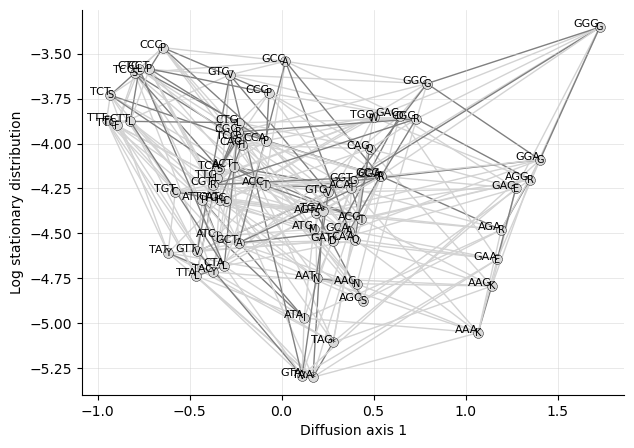

In [2]:
plt.figure(figsize=(7, 5))

codon_coords = dict()
for i, c in enumerate(codons):
    codon_coords[c] = [cv1.real[i], np.log(cstat_freq_norm.real)[i]]

for codon, (x, y) in codon_coords.items():
    plt.scatter(x, y, color=color_gray, zorder = 1, edgecolor = 'black', linewidth=0.3, s = 50)
    plt.text(x, y, codon, fontsize=8, ha='right', zorder = 2)
    plt.text(x, y, codon_to_aa[codon], fontsize=7, ha='center', va='center', zorder = 3)

## edges between codons which are one mutation away from each other
def one_mutation_away(c1, c2):
    return sum(a != b for a, b in zip(c1, c2)) == 1

for c1, c2 in itertools.combinations(codon_coords.keys(), 2):
    if one_mutation_away(c1, c2):
        x1, y1 = codon_coords[c1]
        x2, y2 = codon_coords[c2]
        if codon_to_aa[c1] != codon_to_aa[c2]:
            plt.plot([x1, x2], [y1, y2], color="#D3D3D3", linewidth=1, zorder = 0)
        else:
            plt.plot([x1, x2], [y1, y2], color="#808080", linewidth=1, zorder = 0)

sn.despine()
plt.xlabel('Diffusion axis 1')
plt.ylabel('Log stationary distribution')
plt.grid(True, alpha=0.6, color = '#CCCCCC')

## b: Visualization of all possible amino acids along diffusion axis 1 and their log stationary frequencies.

Amino acids that are mutually accessible via a single nucleotide substitution are connected by edges; the two disconnected serine codon blocks (Ser2 and Ser4) are treated as if they coded for separate amino acids.

Text(0, 0.5, 'Log stationary distribution')

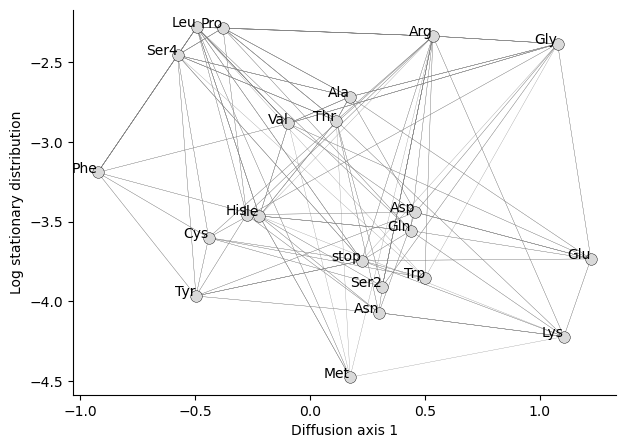

In [3]:
## separating serines into two blocks
aa_full_names_ser = aa_full_names.copy()
aa_full_names_ser['S4'] = 'Ser4'
aa_full_names_ser['S2'] = 'Ser2'
codon_to_aa_ser = codon_to_aa.copy()
codon_to_aa_ser['TCT'] = 'S4'
codon_to_aa_ser['TCC'] = 'S4'
codon_to_aa_ser['TCA'] = 'S4'
codon_to_aa_ser['TCG'] = 'S4'
codon_to_aa_ser['AGT'] = 'S2'
codon_to_aa_ser['AGC'] = 'S2'

plt.figure(figsize=(7, 5))

aa_coords = dict()
for i, aa in enumerate(aa_labels):
    aa_coords[aa] = [av1.real[i], np.log(astat_freq_norm.real)[i]]

for aa, (x, y) in aa_coords.items():
    aa_text = aa_full_names_ser[aa]
    plt.scatter(x, y, color=color_gray, zorder = 1, edgecolor = 'black', s = 70, linewidth=0.3)
    plt.text(x, y, aa_text, fontsize=10, ha='right', zorder = 2)

## edges
for c1, c2 in itertools.combinations(codon_coords.keys(), 2):
    if one_mutation_away(c1, c2):
        x1, y1 = aa_coords[codon_to_aa_ser[c1]]
        x2, y2 = aa_coords[codon_to_aa_ser[c2]]
        if codon_to_aa_ser[c1][0] != codon_to_aa_ser[c2][0]:
            plt.plot([x1, x2], [y1, y2], color='gray', linewidth=0.2, zorder = 0)

sn.despine()
plt.xlabel('Diffusion axis 1')
plt.ylabel('Log stationary distribution')

## c: Stationary frequencies of amino acids under the standard genetic code (colored points) compared with distributions obtained from simulated codon tables (boxplots).

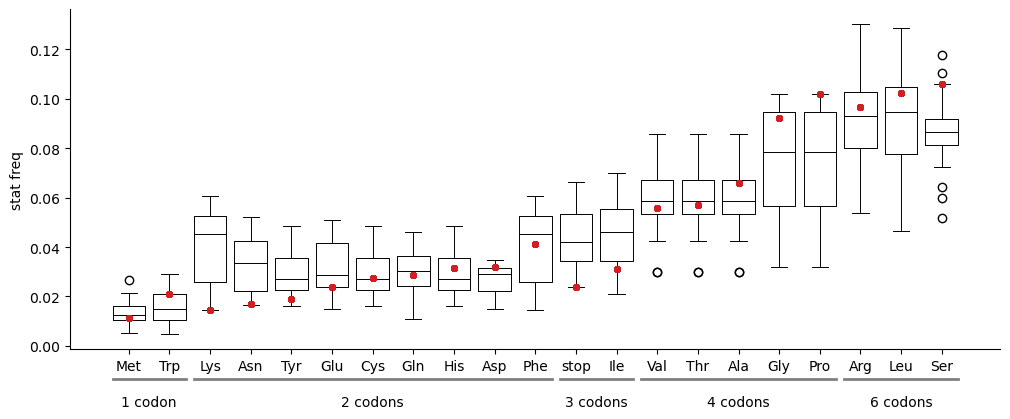

In [4]:
base = 'ATGC'
## shuffling procedure
reshuffled_codon_values = []
for aa in aa_to_codons.keys():
    aa_codons = aa_to_codons[aa]
    actual_eig_values = []
    for codon in aa_codons:
        codon_idx = np.where(codons == codon)[0][0]
        actual_eig_values.append(cstat_freq_norm[codon_idx])
    for perm in itertools.permutations(base):
        new_eig_values = []
        mapping = dict(zip(base, perm))
        trans = str.maketrans(mapping)
        for codon in aa_codons:
            rc = codon.translate(trans)
            rc_idx = np.where(codons == rc)[0][0]
            new_eig_values.append(cstat_freq_norm[rc_idx])
        reshuffled_codon_values.append([aa, len(aa_codons), np.sum(actual_eig_values), np.sum(new_eig_values)])

codon_results = pd.DataFrame(reshuffled_codon_values)
codon_results.columns = ['amino acid', '# codons', 'real table', 'shuffled table']

## sorting amino acids by codon degeneracy and log stat freq value
codon_results = codon_results.sort_values(by=['# codons', 'real table'])
aa_ordered = codon_results[['amino acid']].drop_duplicates()
aa_ordered = aa_ordered['amino acid'].tolist()

## plotting results
fig, ax = plt.subplots(figsize = (12,5))
labels = []
for i, aa in enumerate(aa_ordered):
    sn.boxplot(data = codon_results[codon_results['amino acid'] == aa], y = 'shuffled table', x = i,
               color = 'black', linewidth=0.7, ax = ax, fill = False, showfliers=True, zorder = 1)
    sn.scatterplot(data = codon_results[codon_results['amino acid'] == aa], y = 'real table', x = i,
                   color = color_red, ax = ax, s = 20, edgecolor = None, zorder = 2)
    labels.append(aa_full_names[aa])

ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels)
ax.set_ylabel('stat freq')
sn.despine()

### building runs of '# codons' in the current aa order
aa2n = (codon_results[['amino acid', '# codons']].drop_duplicates('amino acid').set_index('amino acid')['# codons'].to_dict())
counts = [aa2n[aa] for aa in aa_ordered]
runs = []
s = 0
for i in range(1, len(counts) + 1):
    if i == len(counts) or counts[i] != counts[s]:
        runs.append((s, i - 1, counts[s]))
        s = i

### adding a thin line below and adding labels below
fig.subplots_adjust(bottom=0.2)
pos = ax.get_position()
h = 0.12
ax_bar = fig.add_axes([pos.x0, pos.y0 - h, pos.width, h], sharex=ax)
ax_bar.set_ylim(0, 1)
ax_bar.axis('off')
for start, end, n in runs:
    x0, x1 = start - 0.4, end + 0.4
    ax_bar.plot([x0, x1], [0.5, 0.5], lw=2, color='gray', clip_on=False)
    ax_bar.text((x0 + x1) / 2, 0, f"{n} codon" if n == 1 else f"{n} codons", ha="center", va="bottom")

## d: Amino acid frequencies in CDR3 sequences from naive (yellow) and memory (purple) B cells.

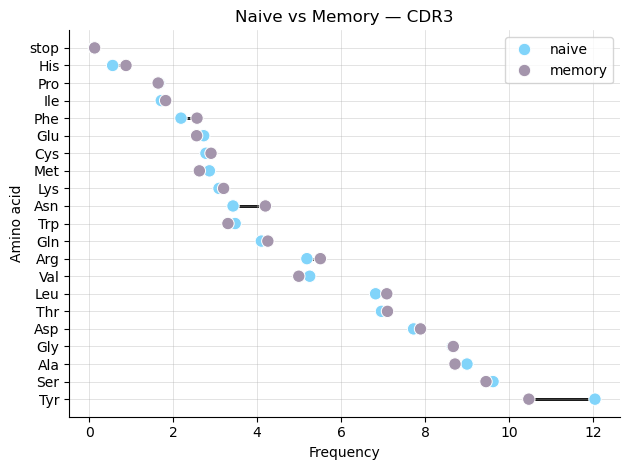

In [5]:
aa_freq = pd.read_csv('data/deWitt_aa-frequenciesallCDR3.tsv', sep = "\t")
## turning fractions into percentages
aa_freq['naive'] = aa_freq['naive']*100
aa_freq['memory'] = aa_freq['memory']*100
aa_freq_ordered = list(aa_freq.sort_values(by='naive')['aa_code'])

plo.dumbbellplot(aa_freq, cdr = "CDR3", order = aa_freq_ordered, labels = aa_full_names)
plt.grid()